# Part 4 | ADIDA — Aggregate–Disaggregate Intermittent Demand Approach
**Guided forecasting tutorial • Supply chain demand planning**

This notebook continues the Croston, SBA and TSB series. We first solve everything manually, then reproduce it in Python. The goal is to understand why aggregation helps, how to choose a bucket size, and how to return the forecast to monthly units.

**Learning path:** historical demand → ADI/CV² → aggregation → SES → disaggregation → sensitivity → model comparison → practice.

We use monthly data, non-overlapping buckets, SES with $\alpha=0.2$, first-bucket initialization and equal-weight disaggregation. These are teaching choices, not mandatory ADIDA settings.

## 1. Why ADIDA?
Croston estimates size divided by interval; SBA corrects its bias; TSB multiplies size by probability. ADIDA instead changes the time frequency to reduce intermittency.

| Month | Jan | Feb | Mar | Apr | May | Jun | Jul | Aug | Sep | Oct | Nov | Dec |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Demand | 10 | 0 | 0 | 12 | 0 | 8 | 0 | 0 | 15 | 0 | 10 | 0 |

Total = 55 units. Five non-zero months and seven zeros.

$$ADI=12/5=2.4$$

Positive sizes are 10, 12, 8, 15, 10; mean = 11; squared deviations sum to 28. Using sample variance:

$$CV^2=\frac{28/4}{11^2}=0.05785$$

Since ADI ≥ 1.32 and CV² < 0.49, the series is intermittent.

,Observations,Zeros,Total,ADI,CV2,Category
Monthly,12,7,55.0,2.4,0.057851,Intermittent


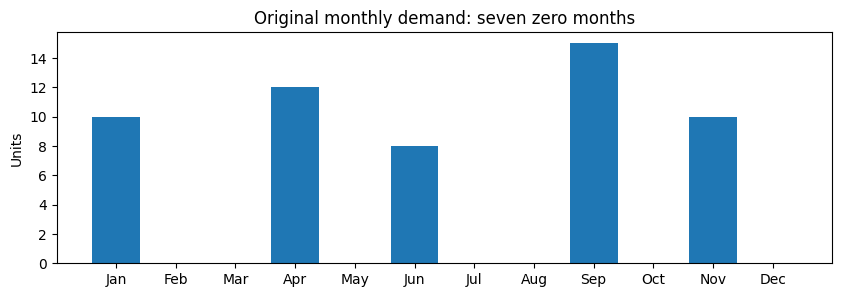

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
months = 'Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec'.split()
y = np.array([10,0,0,12,0,8,0,0,15,0,10,0], dtype=float)
def diagnostics(a):
    a = np.asarray(a); pos = a[a>0]
    adi = len(a)/len(pos) if len(pos) else np.inf
    cv2 = pos.var(ddof=1)/pos.mean()**2 if len(pos)>1 else np.nan
    category = ('Intermittent' if cv2<.49 else 'Lumpy') if adi>=1.32 else ('Smooth' if cv2<.49 else 'Erratic')
    if not np.isfinite(cv2): category = 'Insufficient positive observations'
    return dict(Observations=len(a), Zeros=int((a==0).sum()), Total=a.sum(), ADI=adi, CV2=cv2, Category=category)
display(pd.DataFrame([diagnostics(y)], index=['Monthly']))
plt.figure(figsize=(10,3)); plt.bar(months,y); plt.ylabel('Units'); plt.title('Original monthly demand: seven zero months'); plt.show()

## 2. Temporal aggregation: what is k?
The aggregation level $k$ is the number of original periods in one bucket. For $k=3$, combine consecutive months into quarterly totals:

$$A_j=\sum_{i=1}^{k}D_{(j-1)k+i}$$

| Bucket | Months | Calculation | Total |
|---|---|---|---:|
| 1 | Jan–Mar | 10+0+0 | 10 |
| 2 | Apr–Jun | 12+0+8 | 20 |
| 3 | Jul–Sep | 0+0+15 | 15 |
| 4 | Oct–Dec | 0+10+0 | 10 |

New series: **10, 20, 15, 10**. Total remains 55.

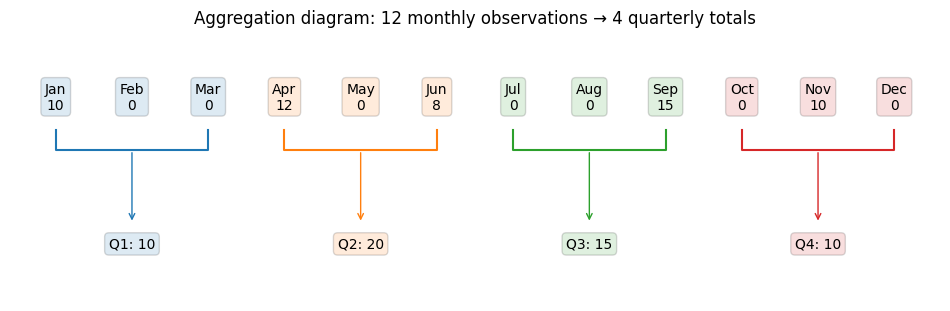

In [2]:
def aggregate(a,k):
    a=np.asarray(a,dtype=float)
    if a.ndim!=1 or not np.isfinite(a).all() or (a<0).any(): raise ValueError('Use finite nonnegative demand.')
    if not isinstance(k,(int,np.integer)) or not 1<=k<=len(a): raise ValueError('k must be an integer from 1 to length of history.')
    r=len(a)%k
    return a[r:].reshape(-1,k).sum(axis=1), r
b,r=aggregate(y,3)
fig,ax=plt.subplots(figsize=(12,3.5)); ax.axis('off'); ax.set_xlim(-.6,11.6); ax.set_ylim(-.3,3)
for i,d in enumerate(y):
    ax.text(i,2.2,f'{months[i]}\n{d:g}',ha='center',va='center',bbox=dict(boxstyle='round',facecolor=f'C{i//3}',alpha=.15))
for j,v in enumerate(b):
    mid=3*j+1; ax.plot([3*j,3*j,3*j+2,3*j+2],[1.8,1.55,1.55,1.8],color=f'C{j}')
    ax.annotate('',xy=(mid,.65),xytext=(mid,1.55),arrowprops=dict(arrowstyle='->',color=f'C{j}'))
    ax.text(mid,.35,f'Q{j+1}: {v:g}',ha='center',bbox=dict(boxstyle='round',facecolor=f'C{j}',alpha=.15))
ax.set_title('Aggregation diagram: 12 monthly observations → 4 quarterly totals'); plt.show()
assert np.array_equal(b,[10,20,15,10]) and b.sum()==y.sum()

## 3. What has aggregation achieved?
The original series has 58.33% zeros; the quarterly series has none. Its ADI is 4/4 = 1. The quarterly mean is 13.75 and sample variance is 22.9167, giving $CV^2=0.12121$. Thus this particular aggregated series is smooth under the usual thresholds.

Aggregation preserves total demand when all buckets are complete, but loses within-bucket timing and reduces the sample size. Four observations are enough for arithmetic practice, not reliable model selection.

,Observations,Zeros,Total,ADI,CV2,Category
Monthly,12,7,55.0,2.4,0.0579,Intermittent
Quarterly,4,0,55.0,1.0,0.1212,Smooth


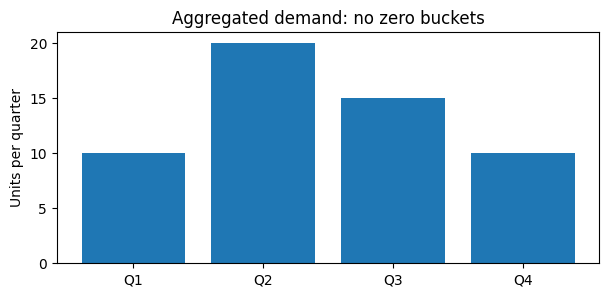

In [3]:
display(pd.DataFrame([diagnostics(y),diagnostics(b)],index=['Monthly','Quarterly']).round(4))
plt.figure(figsize=(7,3)); plt.bar(['Q1','Q2','Q3','Q4'],b); plt.ylabel('Units per quarter'); plt.title('Aggregated demand: no zero buckets'); plt.show()

## 4. Forecast aggregated demand using SES
ADIDA is a framework; SES is one possible base model. Unlike Croston, ordinary SES updates even when its input is zero.

$$L_j=\alpha A_j+(1-\alpha)L_{j-1}$$

$A_j$ is the actual bucket demand; $L_j$ is the new estimate after observing it; $\alpha=0.2$.

### Guided solution
- Q1: initialize $L_1=10$ (no previous estimate).
- Q2: $L_2=0.2(20)+0.8(10)=4+8=12$.
- Q3: $L_3=0.2(15)+0.8(12)=3+9.6=12.6$.
- Q4: $L_4=0.2(10)+0.8(12.6)=2+10.08=12.08$.

The next quarter forecast is **12.08 units**, calculated after Q4. Note the distinction between the forecast issued before a bucket and the level updated after it.

,Actual bucket,Forecast before bucket,Updated level
Q1,10.0,NaN,10.00
Q2,20.0,10.0,12.00
Q3,15.0,12.0,12.60
Q4,10.0,12.6,12.08


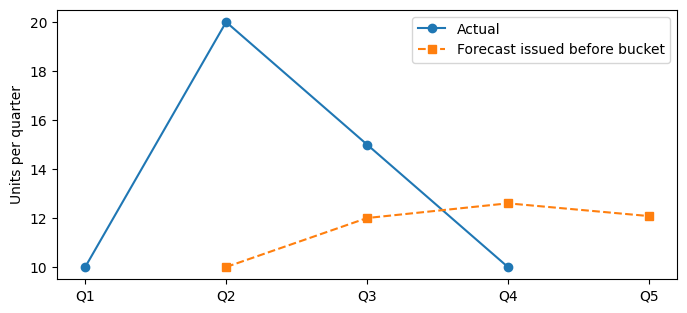

In [4]:
def ses(a,alpha=.2):
    if not 0<alpha<=1: raise ValueError('alpha must be in (0,1].')
    levels=[float(a[0])]
    for v in a[1:]: levels.append(alpha*v+(1-alpha)*levels[-1])
    return np.array(levels)
levels=ses(b)
display(pd.DataFrame({'Actual bucket':b,'Forecast before bucket':np.r_[np.nan,levels[:-1]],'Updated level':levels},index=['Q1','Q2','Q3','Q4']))
plt.figure(figsize=(8,3.5)); plt.plot(range(1,5),b,'o-',label='Actual'); plt.plot(range(2,6),levels,'s--',label='Forecast issued before bucket'); plt.xticks(range(1,6),['Q1','Q2','Q3','Q4','Q5']); plt.ylabel('Units per quarter'); plt.legend(); plt.show()
assert np.allclose(levels,[10,12,12.6,12.08])

## 5. Disaggregation: return to monthly units
We forecast 12.08 units for a three-month bucket. Equal-weight disaggregation divides by $k$:

$$F_{ADIDA}=L_4/k=12.08/3=4.0266667$$

Each of the next three months receives 4.0266667 units of expected demand. The sum is 12.08 (keep full precision until reporting). This does not predict exact order timing. Unequal weights are possible if reliable within-bucket patterns exist; weights must sum to one.

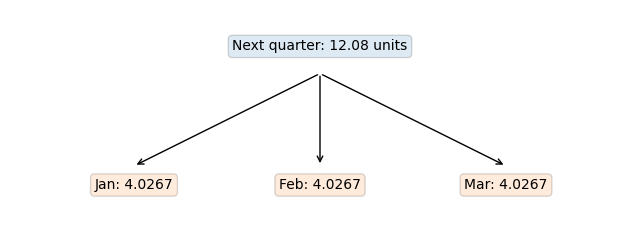

In [5]:
monthly=levels[-1]/3
future=np.repeat(monthly,3)
fig,ax=plt.subplots(figsize=(8,3)); ax.axis('off'); ax.set_xlim(0,10); ax.set_ylim(0,4)
ax.text(5,3.3,'Next quarter: 12.08 units',ha='center',bbox=dict(boxstyle='round',fc='C0',alpha=.15))
for x,m in zip([2,5,8],['Jan','Feb','Mar']):
    ax.annotate('',xy=(x,1.3),xytext=(5,2.9),arrowprops=dict(arrowstyle='->'))
    ax.text(x,.9,f'{m}: {monthly:.4f}',ha='center',bbox=dict(boxstyle='round',fc='C1',alpha=.15))
plt.show()
assert np.isclose(future.sum(),12.08)

## 6. Complete ADIDA algorithm
1. Select $k$.
2. Aggregate complete consecutive buckets, aligned to the forecast origin.
3. Fit the base model at that frequency.
4. Forecast future bucket totals.
5. Disaggregate to the original frequency.

Here SES produces a constant future bucket forecast. For models with trend or seasonality, forecast each future bucket separately before disaggregating.

In [6]:
def adida(a,k=3,alpha=.2,horizon=3):
    if not isinstance(horizon,int) or horizon<1: raise ValueError('Positive integer horizon required.')
    buckets,dropped=aggregate(a,k)
    levels=ses(buckets,alpha)
    return {'buckets':buckets,'dropped':dropped,'levels':levels,'bucket_forecast':levels[-1],
            'monthly_rate':levels[-1]/k,'forecast':np.full(horizon,levels[-1]/k)}
res=adida(y)
print(res)
assert np.isclose(res['monthly_rate'],4.0266666667)

{'buckets': array([10., 20., 15., 10.]), 'dropped': 0, 'levels': array([10.  , 12.  , 12.6 , 12.08]), 'bucket_forecast': np.float64(12.080000000000002), 'monthly_rate': np.float64(4.026666666666667), 'forecast': array([4.02666667, 4.02666667, 4.02666667])}


## 7. How do we choose k?
**ADI heuristic:** $k=\max(1,\operatorname{round}(ADI))=2$ here. This is a heuristic, not an optimality guarantee.

**Lead time:** if procurement lead time is 3 months, $k=3$ can align with lead-time demand. For periodic review, lead time plus review interval may be relevant.

**Backtesting:** compare candidate k values on identical historical forecast origins and horizons. Fit only using information available at each origin. Too large a k gives too few observations.

For the same data and alpha, compare k = 1, 2, 3, 4, 6. For k=2 the series is 10,12,8,0,15,10; k=4 gives 22,8,25; k=6 gives 30,25.

,k,Buckets,Number,Zeros,Bucket forecast,Monthly forecast
0,1,"[10, 0, 0, 12, 0, 8, 0, 0, 15, 0, 10, 0]",12,7,4.8171,4.8171
1,2,"[10, 12, 8, 0, 15, 10]",6,1,9.4790,4.7395
2,3,"[10, 20, 15, 10]",4,0,12.0800,4.0267
3,4,"[22, 8, 25]",3,0,20.3600,5.0900
4,6,"[30, 25]",2,0,29.0000,4.8333


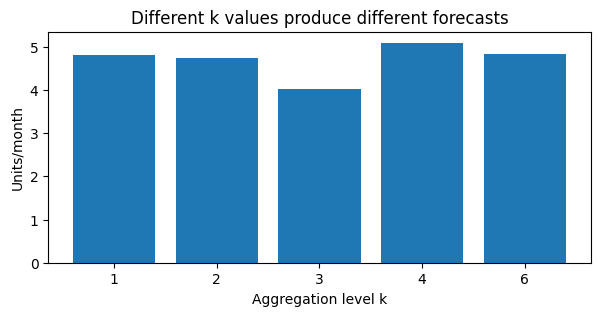

In [7]:
rows=[]
for k in [1,2,3,4,6]:
    r=adida(y,k)
    rows.append({'k':k,'Buckets':r['buckets'].astype(int).tolist(),'Number':len(r['buckets']),'Zeros':int((r['buckets']==0).sum()),'Bucket forecast':r['bucket_forecast'],'Monthly forecast':r['monthly_rate']})
comparison=pd.DataFrame(rows); display(comparison.round(4))
plt.figure(figsize=(7,3)); plt.bar(comparison.k.astype(str),comparison['Monthly forecast']); plt.xlabel('Aggregation level k'); plt.ylabel('Units/month'); plt.title('Different k values produce different forecasts'); plt.show()

## 8. Guided experiment: change k and alpha
Edit the two values in the next cell and rerun. Examine how bucket counts, zeros, smoothed estimates and forecasts change. A larger alpha gives more weight to recent aggregate demand. A larger k changes the units of the underlying forecast.

,Bucket actual,Updated SES level
0,10.0,10.00
1,20.0,12.00
2,15.0,12.60
3,10.0,12.08


Bucket forecast = 12.0800; monthly forecast = 4.0267


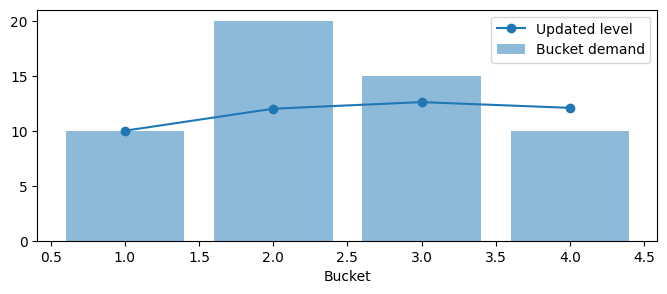

In [8]:
k=3
alpha=.2
r=adida(y,k,alpha)
display(pd.DataFrame({'Bucket actual':r['buckets'],'Updated SES level':r['levels']}))
print(f"Bucket forecast = {r['bucket_forecast']:.4f}; monthly forecast = {r['monthly_rate']:.4f}")
plt.figure(figsize=(8,3)); x=np.arange(1,len(r['buckets'])+1); plt.bar(x,r['buckets'],alpha=.5,label='Bucket demand'); plt.plot(x,r['levels'],'o-',label='Updated level'); plt.xlabel('Bucket'); plt.legend(); plt.show()

,0.1,0.2,0.3,0.5,0.8
k,,,,,
1,6.073,4.817,4.331,3.528,1.696
2,4.813,4.740,4.759,4.969,5.235
3,3.753,4.027,4.173,4.167,3.707
4,5.260,5.090,4.990,5.000,5.540
6,4.917,4.833,4.750,4.583,4.333


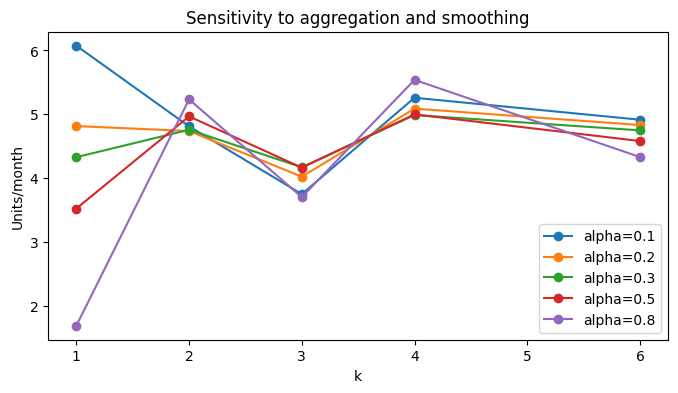

In [9]:
sensitivity=pd.DataFrame({a:[adida(y,k,a)['monthly_rate'] for k in [1,2,3,4,6]] for a in [.1,.2,.3,.5,.8]},index=[1,2,3,4,6]); sensitivity.index.name='k'; display(sensitivity.round(3))
plt.figure(figsize=(8,4))
for a in sensitivity.columns: plt.plot(sensitivity.index,sensitivity[a],'o-',label=f'alpha={a}')
plt.xlabel('k'); plt.ylabel('Units/month'); plt.legend(); plt.title('Sensitivity to aggregation and smoothing'); plt.show()

## 9. Incomplete buckets
For 14 monthly observations with $k=3$, retain the most recent 12 and drop the oldest two, creating four complete buckets. This is one standard alignment choice; other methods exist. Do not pad missing values with zero. Missing data are not observed zero demand. Unlike the divisible example, discarded history means total demand across the original 14 periods is not preserved.

Discarded: [1 2] Retained: [ 3  4  5  6  7  8  9 10 11 12 13 14] Buckets: [12. 21. 30. 39.]


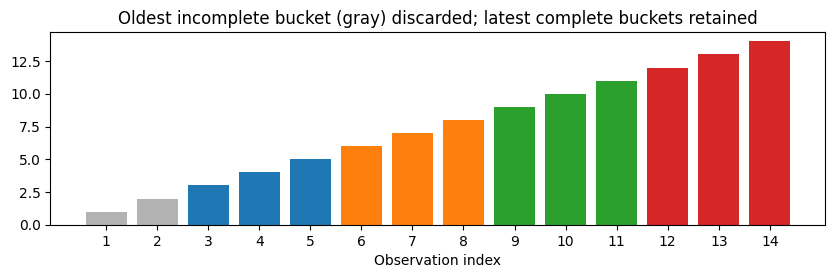

In [10]:
example=np.arange(1,15); a,drop=aggregate(example,3)
print('Discarded:',example[:drop], 'Retained:',example[drop:], 'Buckets:',a)
assert a.tolist()==[12,21,30,39]
plt.figure(figsize=(10,2.5)); plt.bar(range(1,15),example,color=['0.7']*2+[f'C{j}' for j in range(4) for _ in range(3)]); plt.xticks(range(1,15)); plt.xlabel('Observation index'); plt.title('Oldest incomplete bucket (gray) discarded; latest complete buckets retained'); plt.show()

## 10. Compare with Croston, SBA and TSB
Use the same monthly data, $\alpha=\beta=0.2$, initial interval 1 and initial probability 1. For Croston and SBA, update size and interval only on positive demand. TSB updates probability every period. All reported forecasts are after December and predict the next month.

$$F_C=Z/P,\qquad F_{SBA}=(1-\alpha/2)F_C,\qquad F_{TSB}=Zp$$

A lower forecast is not automatically a better forecast.

Historical mean    4.5833
Croston            5.8014
SBA                5.2212
TSB                4.6680
ADIDA (k=3)        4.0267
Name: Units/month, dtype: float64

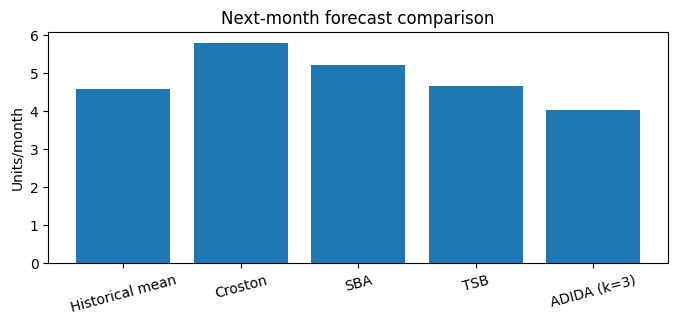

In [11]:
def previous_models(a,alpha=.2,beta=.2):
    a=np.asarray(a); first=np.flatnonzero(a>0)
    if not len(first): return {'Croston':0.,'SBA':0.,'TSB':0.}
    last=int(first[0]); z=float(a[last]); P=float(last+1); p=1/P
    for i in range(last+1,len(a)):
        d=a[i]; p=(1-beta)*p+beta*(d>0)
        if d>0:
            z=alpha*d+(1-alpha)*z; P=alpha*(i-last)+(1-alpha)*P; last=i
    return {'Croston':z/P,'SBA':(1-alpha/2)*z/P,'TSB':z*p}
model_values={'Historical mean':y.mean(),**previous_models(y),'ADIDA (k=3)':adida(y)['monthly_rate']}
display(pd.Series(model_values,name='Units/month').round(4))
plt.figure(figsize=(8,3)); plt.bar(list(model_values),list(model_values.values())); plt.ylabel('Units/month'); plt.title('Next-month forecast comparison'); plt.xticks(rotation=15); plt.show()

## 11. Mini backtesting demonstration
A rolling-origin evaluation fits each candidate only on past observations and compares its forecast against the same future actuals. Here we use one-month MAE and signed bias (forecast minus actual). This tiny dataset gives only six evaluation origins; results are illustrative, not robust evidence. For replenishment, evaluate cumulative lead-time errors and inventory outcomes too.

In [12]:
records=[]
for origin in range(6,len(y)):
    for k in [1,2,3]:
        pred=adida(y[:origin],k,horizon=1)['monthly_rate']
        records.append({'k':k,'Month':months[origin],'Actual':y[origin],'Forecast':pred,'Error':pred-y[origin],'Absolute error':abs(pred-y[origin])})
backtest=pd.DataFrame(records)
display(backtest.groupby('k').agg(MAE=('Absolute error','mean'),Bias=('Error','mean'),Origins=('Error','size')).round(4))

,MAE,Bias,Origins
k,,,
1,6.6195,1.3298,6
2,4.8853,-0.5672,6
3,5.6444,-0.1156,6


## 12. Practice questions with worked solutions
**Q1.** With k=2, aggregate the original data. **Solution:** 10,12,8,0,15,10. SES levels with alpha=.2: 10,10.4,9.92,7.936,9.3488,9.47904. Divide by two: **4.73952 units/month**.

**Q2.** With k=3 and alpha=.5, find the monthly forecast. **Solution:** levels 10,15,15,12.5; 12.5/3 = **4.16667**.

**Q3.** A 4-month bucket forecast is 24 units. What is the monthly forecast? **Solution:** 24/4 = **6 units/month**.

**Q4.** If 17 observations are available and k=4, how many are retained? **Solution:** 16 retained, 1 oldest discarded, 4 complete buckets.

**Q5.** Does ADIDA always eliminate zeros? **Solution:** No. A bucket is zero when every observed demand within it is zero. Larger buckets may reduce the zero fraction, but may also lose useful temporal information.

In [13]:
assert np.isclose(adida(y,2)['monthly_rate'],4.73952)
assert np.isclose(adida(y,3,.5)['monthly_rate'],12.5/3)
assert aggregate(np.arange(17),4)[1]==1
assert np.all(adida(np.zeros(12))['forecast']==0)
print('All numerical checks passed.')

All numerical checks passed.


## 13. Revision and limitations
| Advantages | Limitations |
|---|---|
| Can reduce intermittency | Fewer observations for training |
| Flexible base forecasting model | Sensitive to k and bucket alignment |
| Useful for lead-time demand | May hide seasonality and timing |
| Simple equal disaggregation | Does not explicitly estimate occurrence probability |

**Key formulas:** $A_j=\sum_i D_{(j-1)k+i}$; $L_j=\alpha A_j+(1-\alpha)L_{j-1}$; $F=L_j/k$.

Final worked example: 12 months → 4 buckets → SES forecast 12.08 units/quarter → **4.0267 units/month**. ADIDA is not limited to intermittent demand, but aggregation must be validated rather than assumed beneficial.

**Reference:** Nikolopoulos, Syntetos, Boylan, Petropoulos & Assimakopoulos (2011). An aggregate–disaggregate intermittent demand approach (ADIDA) to forecasting: An empirical proposition and analysis. *Journal of the Operational Research Society*, 62, 544–554. https://doi.org/10.1057/jors.2010.32

**Next lesson:** IMAPA combines forecasts across multiple aggregation levels rather than selecting a single k.